# Evaluation & benchmarking: EGFR + HER2 dual-target prototype (Person 5)

Reads the outputs committed by Persons 1-4, computes validity / uniqueness / novelty / QED / SA / dual-docking metrics,
and compares **single-target generation + filtering** with the **GA** and **RL** optimisers.
Run from anywhere; it locates the repository root automatically. Full interpretation: `RESULTS_SUMMARY.md`.

**Read this first.** No truly *dual-conditioned* generator output exists in the repo (`DUAL_TARGET.md`: the pool is a generate-and-filter set).
The GA/RL molecules are 2D SMILES built from known EGFR/HER2 actives, not output of the 3D diffusion model, and they were optimised on the same docking reward used to score them.

In [1]:
import importlib.util, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Outputs-git").exists())
spec = importlib.util.spec_from_file_location("ev", root / "Scripts" / "09_evaluate_benchmark.py")
ev = importlib.util.module_from_spec(spec); sys.modules["ev"] = ev; spec.loader.exec_module(ev)
ev.main(["--root", str(root)])          # regenerates every table/figure in Outputs-git/evaluation/
EV = root / "Outputs-git" / "evaluation"
print(ev.CRITERIA)

[1/6] loading reference actives and candidate sets


      reference actives: 1616 unique (106 listed as active for both targets)
[2/6] computing per-molecule properties, novelty and docking descriptors


[3/6] group-level metrics


[4/6] statistics, QA checks, shortlist
[5/6] figures


[6/6] done -> /tmp/claude-0/-home-claude/1b1abf3a-99cb-5945-931e-263011dd6ca5/scratchpad/repo_clone/repo/Outputs-git/evaluation

QA flags:
                                      check status                                                                                                                                                                                      detail
                             Redocking EGFR   FAIL                                                                                                               top-pose RMSD 2.47 A (pass <= 2.0); best of 9 modes 1.34 A; best score -11.10
 Docking box HER2 centred on crystal ligand   FAIL box centre is 25.1 A from the 03Q ligand centre; box sides 36 x 45 x 53 A (Person 1's docking_boxes.json is wrong for this target; Person 4's script uses docking_boxes_fixed.json instead)
   Box volume EGFR vs HER2 (committed json)   WARN                                                                             HER2 box is 11.0x

## 1. Group metrics

In [2]:
m = pd.read_csv(EV/"metrics_summary.csv").set_index("group")
cols = ["n_logged","rdkit_valid_pct","unique_pct","gate_pass_pct","docked_pct","n_known_rediscovered","novelty_mean","diversity",
        "qed_median","sa_median","dock_EGFR_median","dock_HER2_median","dock_diff_median","lig_eff_median",
        "n_dual_hit","n_dual_hit_novel","n_dual_lead","dual_lead_pct_of_logged"]
m[cols].round(2).T

group,EGFR-gen,HER2-gen,Pool,GA-optimised,RL-optimised,Known actives,Known dual actives
n_logged,20.00,18.00,38.00,66.00,237.00,1616.00,106.00
rdkit_valid_pct,100.00,100.00,100.00,NaN,54.37,100.00,100.00
unique_pct,100.00,100.00,100.00,100.00,100.00,100.00,100.00
gate_pass_pct,35.00,44.44,39.47,100.00,94.94,NaN,NaN
docked_pct,30.00,38.89,34.21,100.00,94.94,NaN,NaN
n_known_rediscovered,0.00,0.00,0.00,18.00,22.00,NaN,NaN
novelty_mean,0.83,0.82,0.83,0.37,0.40,NaN,NaN
diversity,0.91,0.91,0.91,0.77,0.76,0.79,0.71
qed_median,0.34,0.40,0.35,0.52,0.60,0.42,0.44
sa_median,4.57,4.54,4.54,2.89,2.41,2.66,2.66


*Validity:* baseline = RDKit parse (38/38); RL = mean parse rate of sampled SMILES; GA logs only valid molecules (no record). *Novelty* is meaningless for the baseline pool (junk molecules are trivially dissimilar to real inhibitors). *Dual lead* = passes gate, both scores <= -8, |Δ| <= 1, QED >= 0.5, SA <= 4.5 and novelty > 0.3 (so rediscovered known actives are excluded).

## 2. Yield and dual docking

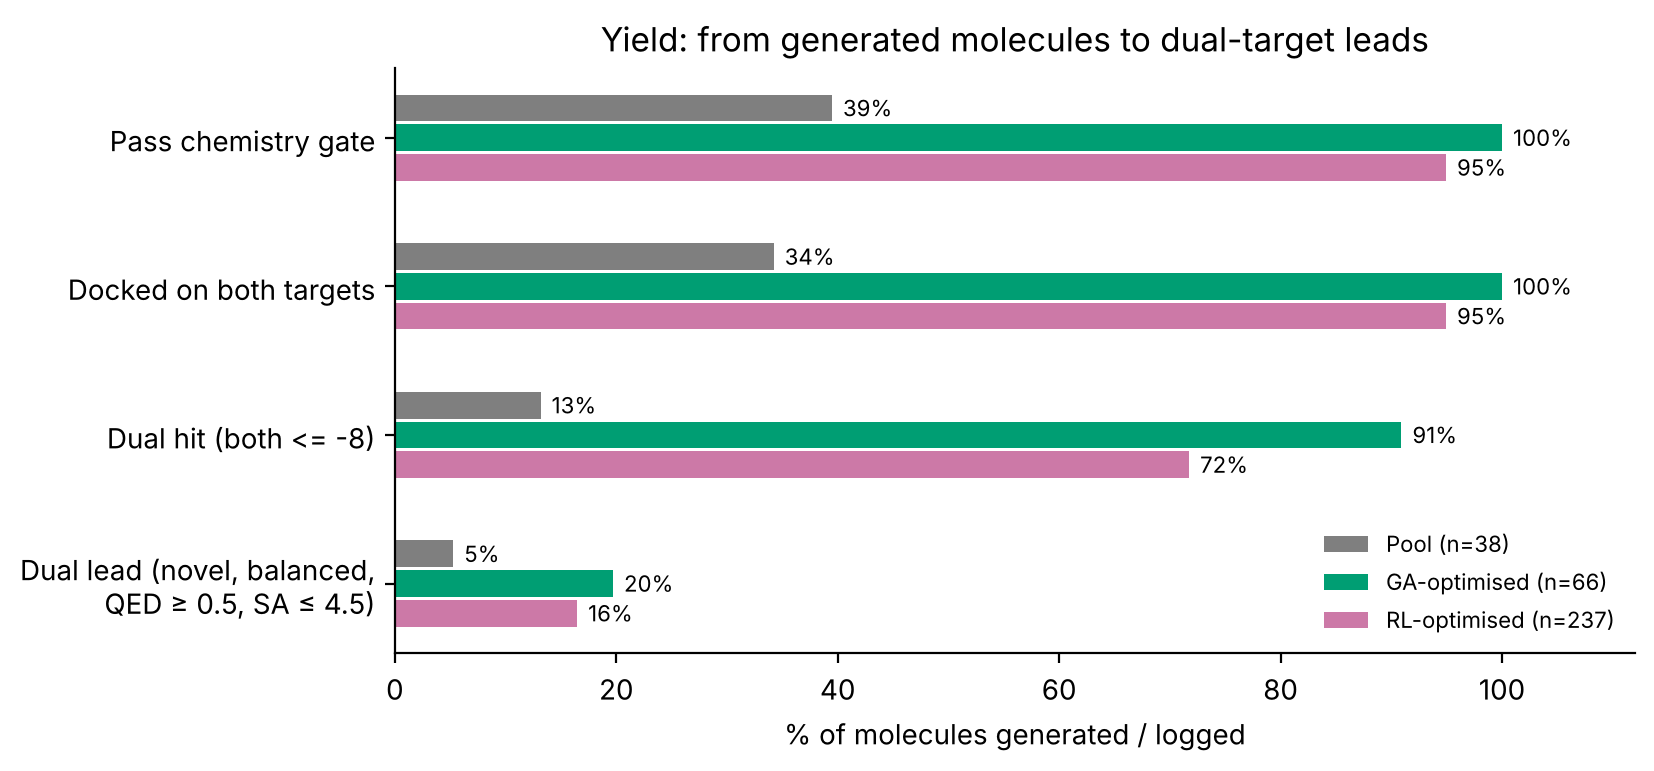

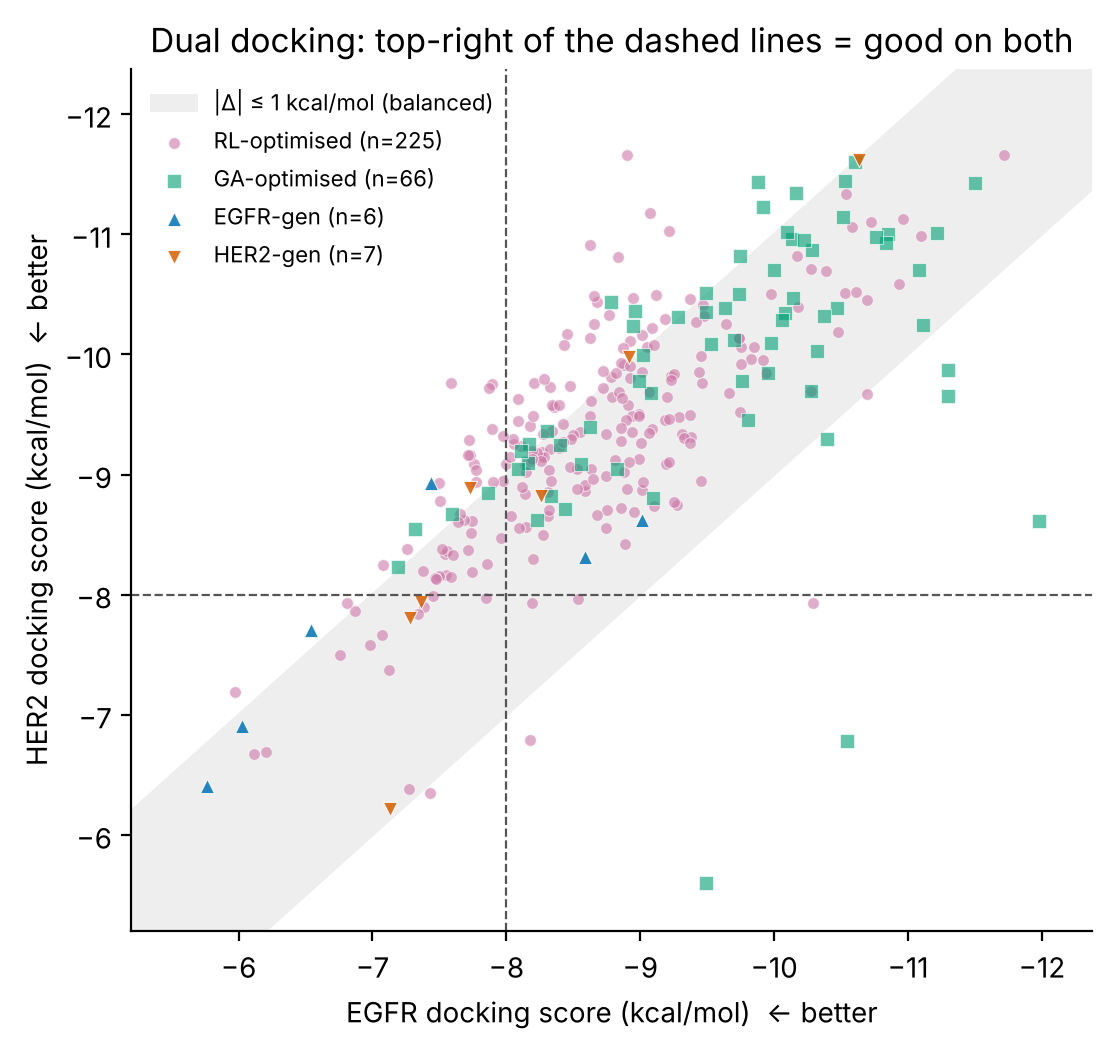

In [3]:
display(Image(EV/"figures"/"fig1_yield_funnel.png")); display(Image(EV/"figures"/"fig2_dual_docking_scatter.png", width=560))

## 3. Properties

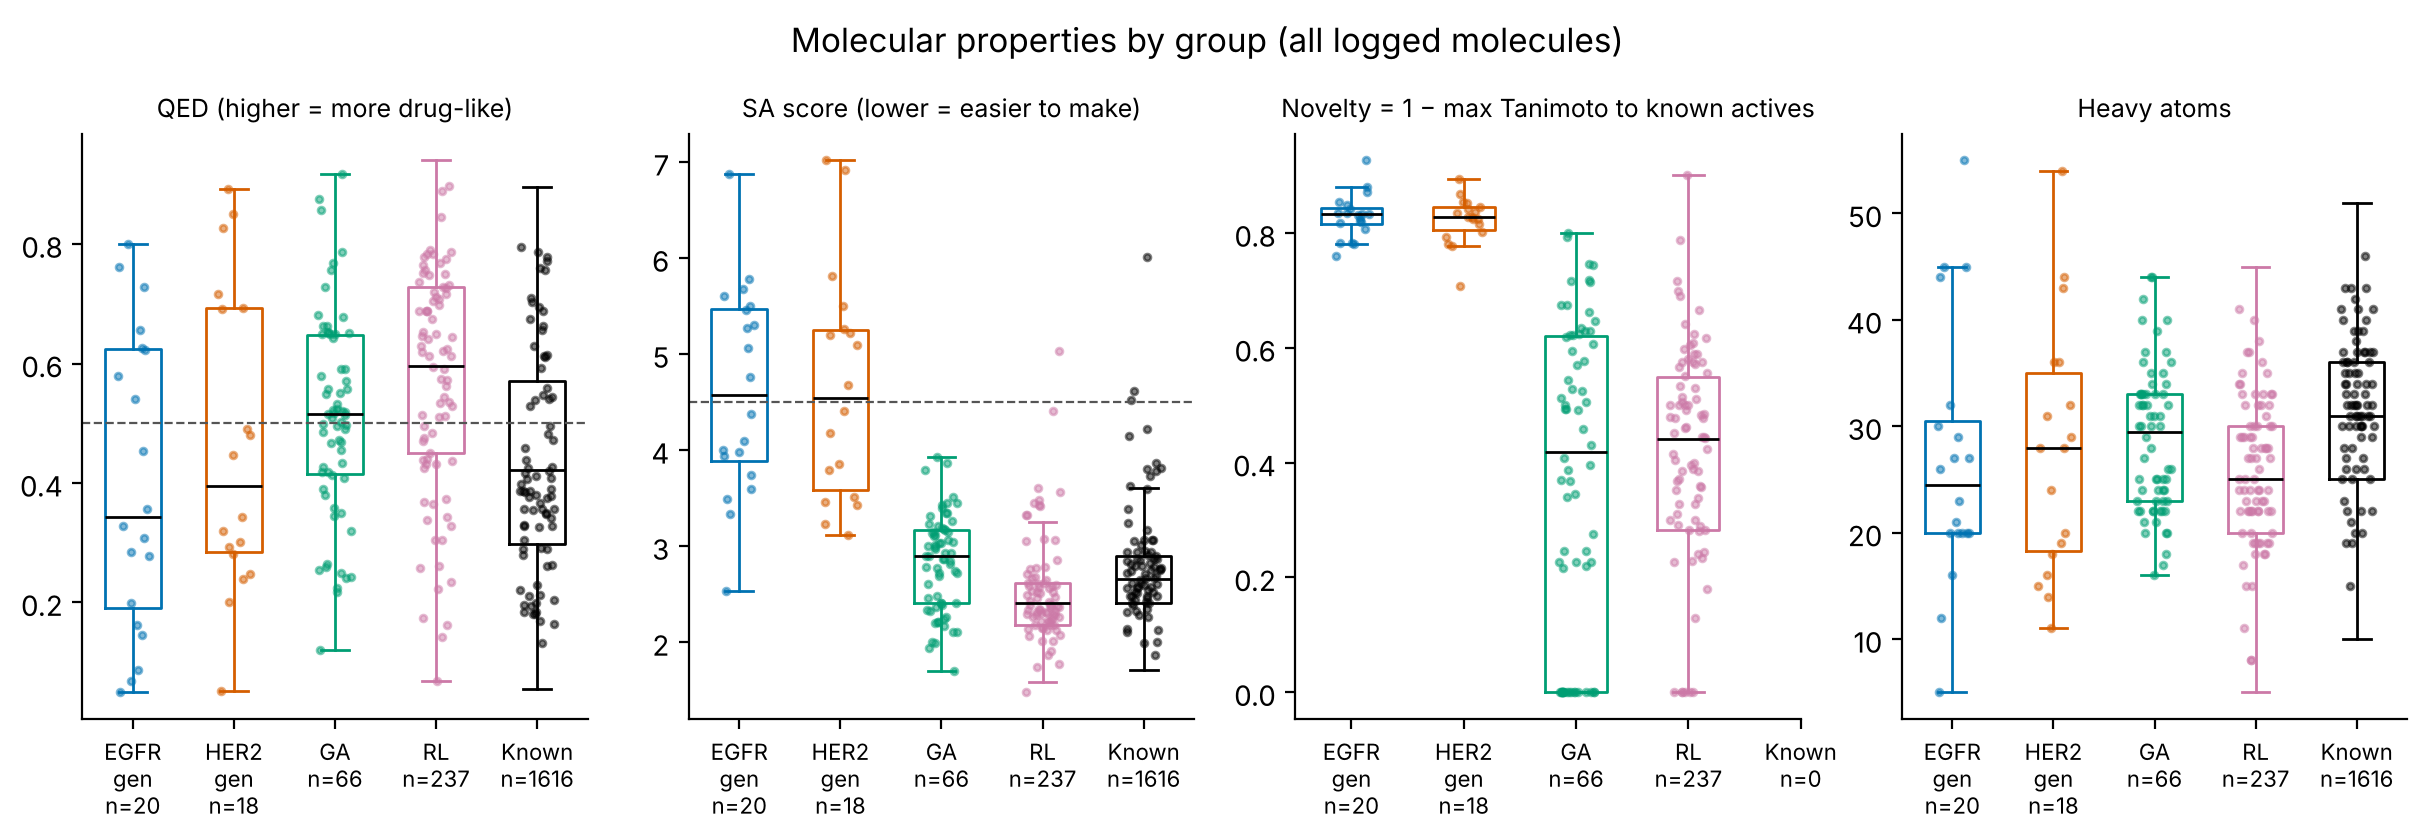

In [4]:
display(Image(EV/"figures"/"fig3_property_distributions.png"))

## 4. Optimiser behaviour

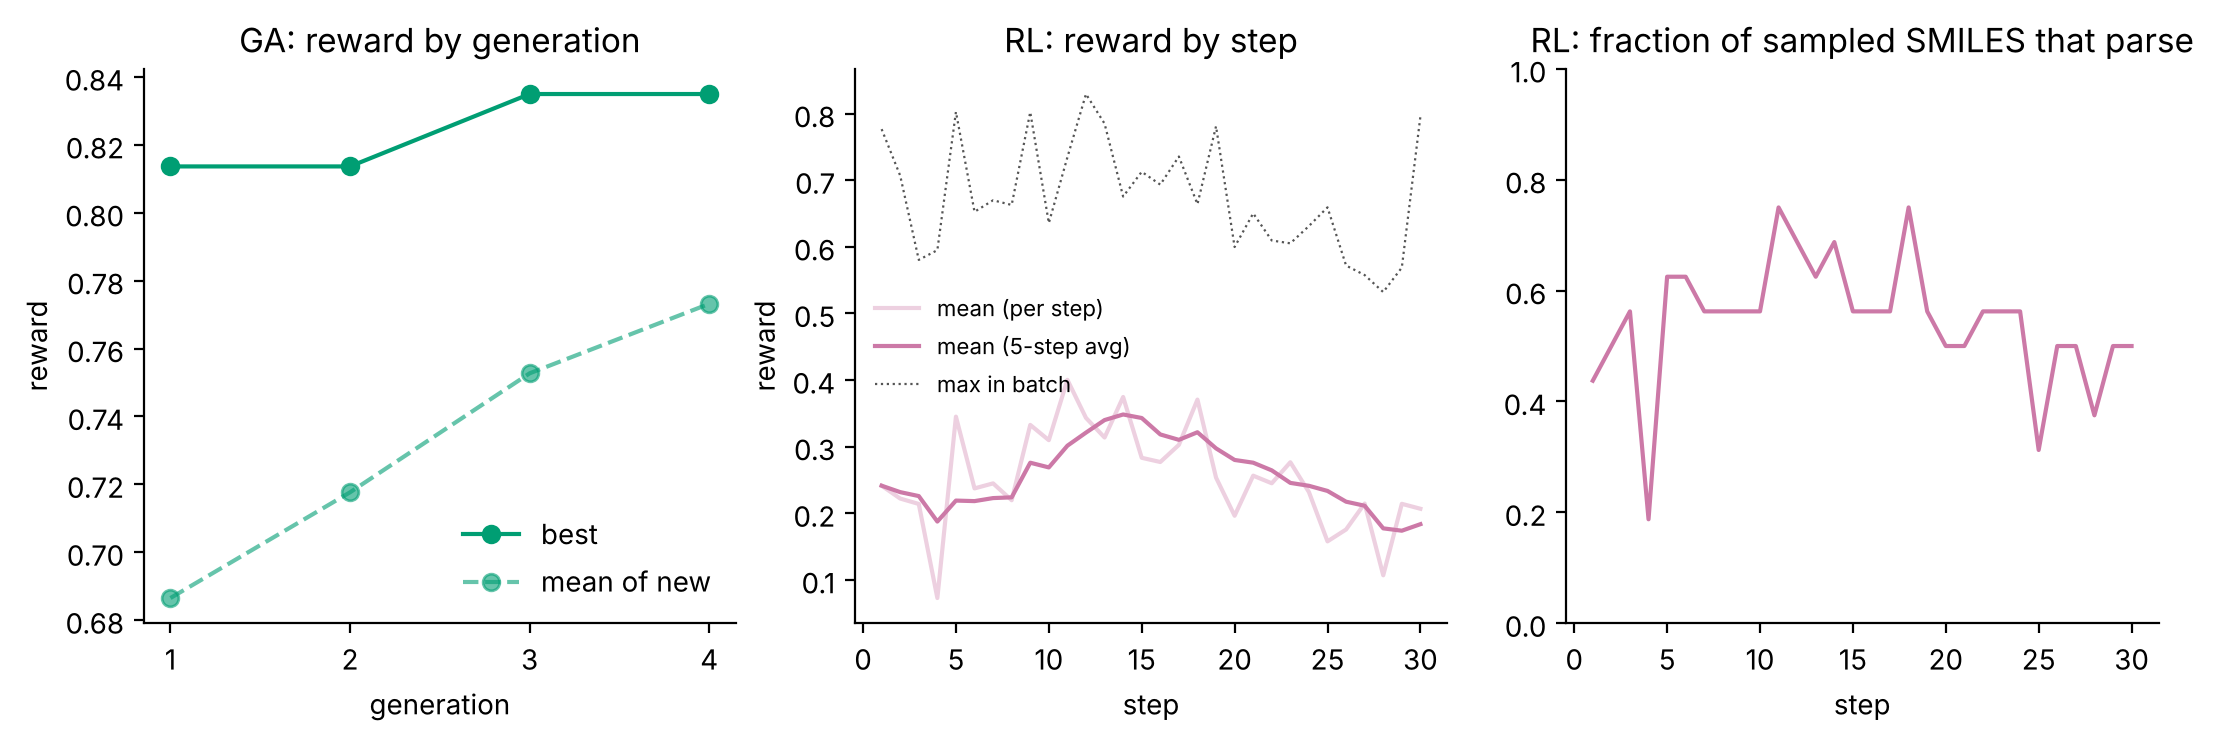

In [5]:
display(Image(EV/"figures"/"fig4_optimisation_curves.png"))

## 5. Statistics (optimisers vs. filtered single-target baseline, n=13 docked) and size bias
`effect_a_gt_b`: +1 means group A is always larger, −1 always smaller (for `dock_mean`, negative = A docks better). The baseline n is small; treat p-values as indicative only.

In [6]:
display(pd.read_csv(EV/"statistical_tests.csv").round(4)); display(pd.read_csv(EV/"size_bias.csv").round(3))

,comparison,subset,metric,n_a,n_b,median_a,median_b,effect_a_gt_b,p_value
0,GA-optimised vs filtered single-target baseline,all logged,dock_mean,66,13,-9.9555,-8.1820,-0.7203,0.0000
1,GA-optimised vs filtered single-target baseline,all logged,lig_eff,66,13,0.3398,0.3557,-0.0443,0.8068
2,GA-optimised vs filtered single-target baseline,all logged,qed,66,13,0.5152,0.6557,-0.2727,0.1235
3,GA-optimised vs filtered single-target baseline,all logged,sa_score,66,13,2.8947,3.7428,-0.8625,0.0000
4,GA-optimised vs filtered single-target baseline,novel only,dock_mean,40,13,-9.8280,-8.1820,-0.6962,0.0002
5,GA-optimised vs filtered single-target baseline,novel only,lig_eff,40,13,0.3477,0.3557,0.0192,0.9259
6,GA-optimised vs filtered single-target baseline,novel only,qed,40,13,0.4963,0.6557,-0.2808,0.1339
7,GA-optimised vs filtered single-target baseline,novel only,sa_score,40,13,2.9969,3.7428,-0.7962,0.0000
8,RL-optimised vs filtered single-target baseline,all logged,dock_mean,225,13,-8.9575,-8.1820,-0.5118,0.0019
9,RL-optimised vs filtered single-target baseline,all logged,lig_eff,225,13,0.3603,0.3557,0.0311,0.8521


,group,n,spearman_heavy_atoms_vs_dock,p_value
0,GA-optimised,66,-0.445,0.0
1,RL-optimised,225,-0.500,0.0


## 6. Shortlist (novel, gate-passing, docked; ranked by Person 4's reward)

,rank,canonical,group,candidate_id,reward,dock_EGFR,dock_HER2,dock_diff,qed,sa_score,heavy_atoms,novelty,max_sim_known,nearest_known_chembl,dual_hit_novel,dual_lead
0,1,O=C(C#CCNN1CCOCC1)Nc1cc2c(-c3ccc(F)c(Br)c3)ncn...,GA-optimised,NaN,0.83,-10.85,-11.00,0.15,0.55,3.23,31,0.41,0.59,CHEMBL204638,True,True
1,2,Cc1cc(-c2ccc3ncnc(NCCN4CCOCC4)c3c2)ccc1NCc1ccccn1,RL-optimised,NaN,0.83,-11.10,-10.98,0.11,0.41,2.45,34,0.55,0.45,CHEMBL165731,True,False
2,3,N#Cc1ccc(Cl)cc1Nc1nc(O)nc2cc3ccccc3c(O)c12,GA-optimised,NaN,0.82,-11.08,-10.70,0.38,0.45,2.72,26,0.72,0.28,CHEMBL96096,True,False
3,4,N#Cc1ccc(Cl)cc1Nc1ncnc2cc3ccccc3cc12,GA-optimised,NaN,0.82,-10.51,-11.14,0.63,0.52,2.21,24,0.53,0.47,CHEMBL63786,True,True
4,5,Fc1cccc(Nc2ncnc3ccc(NCC#CCN4CCOCC4)cc23)c1,RL-optimised,NaN,0.80,-10.27,-10.71,0.44,0.65,2.59,29,0.39,0.61,CHEMBL93386,True,True
5,6,O=[N+]([O-])c1ccc2ncnc(Nc3ccc(OCc4ccccc4)c(Cl)...,RL-optimised,NaN,0.80,-10.97,-11.13,0.16,0.33,2.09,29,0.43,0.57,CHEMBL329161,True,False
6,7,Cc1cc2c(CN3CCC(F)(c4ccccc4Cl)CC3)cc3n[nH]cc3c2o1,HER2-gen,P3_023,0.80,-10.63,-11.62,0.99,0.48,3.11,28,0.78,0.22,CHEMBL36967,True,False
7,8,O=C(C#CCNN1CCOCC1)Nc1cc2c(-c3cc(Br)c(F)cc3F)nc...,GA-optimised,NaN,0.79,-10.76,-10.98,0.22,0.42,3.34,32,0.46,0.54,CHEMBL204638,True,False
8,9,Cc1cccc2cc3c(Nc4cccc(Cl)c4)ncnc3cc12,GA-optimised,NaN,0.79,-10.60,-11.60,1.00,0.50,2.10,23,0.37,0.63,CHEMBL7917,True,False
9,10,CC(C)C(=O)NCCn1ccc2ncnc(Nc3ccc4c(cnn4Cc4ccccc4...,RL-optimised,NaN,0.79,-10.72,-11.10,0.38,0.36,2.62,34,0.45,0.55,CHEMBL429827,True,False


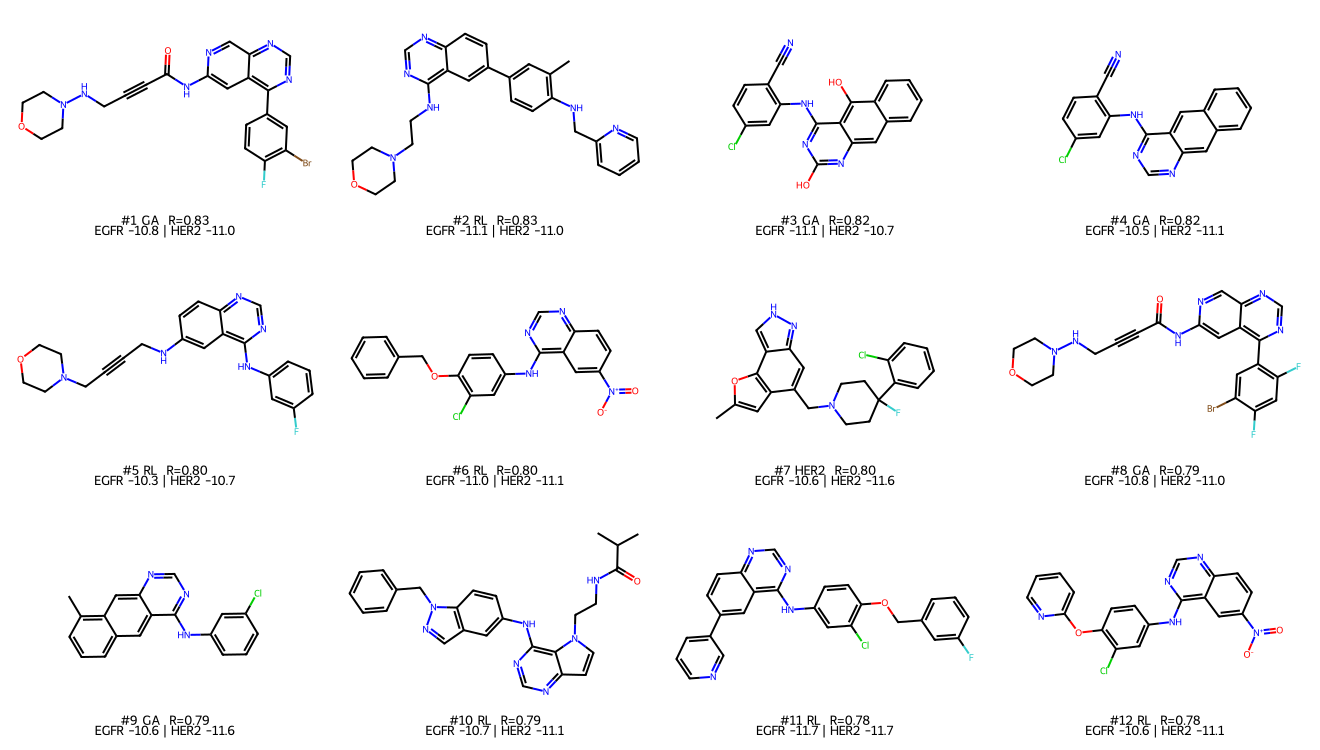

In [7]:
display(pd.read_csv(EV/"final_candidate_shortlist.csv").round(2)); display(Image(EV/"figures"/"fig5_top_candidates.png"))

## 7. Automated QA checks on the inputs

In [8]:
pd.read_csv(EV/"qa_checks.csv").style.set_properties(**{"text-align":"left","white-space":"pre-wrap"})

,check,status,detail
0,Redocking EGFR,FAIL,top-pose RMSD 2.47 A (pass <= 2.0); best of 9 modes 1.34 A; best score -11.10
1,Redocking HER2,OK,top-pose RMSD 0.62 A (pass <= 2.0); best of 4 modes 0.62 A; best score -11.49
2,Docking box EGFR centred on crystal ligand,OK,box centre is 0.7 A from the FMM ligand centre; box sides 20 x 17 x 23 A
3,Docking box HER2 centred on crystal ligand,FAIL,box centre is 25.1 A from the 03Q ligand centre; box sides 36 x 45 x 53 A (Person 1's docking_boxes.json is wrong for this target; Person 4's script uses docking_boxes_fixed.json instead)
4,Box volume EGFR vs HER2 (committed json),WARN,HER2 box is 11.0x the volume of EGFR; scores are only comparable if both targets were docked with similar boxes
5,docking_boxes_fixed.json committed,WARN,"Person 4's script reads/writes docking_boxes_fixed.json but it is not in the repo, so the boxes behind the committed scores cannot be verified"
6,Anchor residue numbers usable (config.yaml),FAIL,cleaned PDB is renumbered 1..352 so UniProt anchors (EGFR hinge 793...) match nothing; script 03's HER2->EGFR alignment is silently skipped and no aligned file exists
7,3D geometry of single-target molecules,WARN,7 of 38 molecules contain a bond shorter than 1.1 A (physically impossible; e.g. O-O at 0.4 A); many more have stretched bonds
8,Vina exhaustiveness (script default),WARN,default is 4; the script itself recommends 8-32 for final numbers. Confirm which value produced the committed scores (scores at low exhaustiveness are noisy)
9,Docking failures (baseline pool),WARN,2 of 15 gate-passing baseline molecules have no docking score
